# 🎓 Logistic Regression — Placement Prediction

**Dataset:** `placement.csv` — 550 students
**Goal:** predict whether a student gets placed — `placed` = Yes (placed) or No (not placed)

## 📘 What is Logistic Regression?

### Definition

**Logistic Regression** is a supervised machine learning algorithm used for **classification** problems. It predicts the **probability** that an input belongs to the positive class (class 1).

It works in three steps:
1. It calculates a weighted sum of the input features plus a bias: **z = w₁x₁ + w₂x₂ + … + wₙxₙ + b**
2. It passes z through the **sigmoid function**, **σ(z) = 1 / (1 + e⁻ᶻ)**, which converts any real number into a probability between 0 and 1.
3. It compares the probability with a **threshold** (usually 0.5): if p ≥ 0.5 the output is class 1, otherwise class 0.

### Formulas

| Step | Formula |
|---|---|
| Weighted sum (raw score) | z = w₁x₁ + w₂x₂ + … + wₙxₙ + b |
| Sigmoid (probability) | p = σ(z) = 1 / (1 + e⁻ᶻ) |
| Decision (threshold 0.5) | class = 1 if p ≥ 0.5, else 0 |

### How sigmoid behaves

| z | −4 | −2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| σ(z) | 0.02 | 0.12 | **0.50** | 0.88 | 0.98 |

- Large positive z → p close to 1
- Large negative z → p close to 0
- z = 0 → p = 0.5 exactly

### Key points

- It is a **classification** algorithm, even though its name contains "regression".
- The output of sigmoid is always between 0 and 1, so it can be read as a probability.
- The **weights (w)** and the **bias / intercept (b)** are learned from the training data.
- It is mainly used for **binary classification**: placed / not placed, pass / fail, spam / not spam.
- In scikit-learn: `from sklearn.linear_model import LogisticRegression`

## 📥 1. Load the data

> **Flow:** import libraries → read the CSV → first look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
# numpy 2.0 + macOS Accelerate prints a harmless "encountered in matmul" warning inside sklearn
warnings.filterwarnings("ignore", message=".*encountered in matmul")

In [2]:
df = pd.read_csv('../Data/placement.csv')
df.head()

,student_id,cgpa,twelfth_percent,branch,internships,projects,backlogs,prep_hours,communication_score,hostel,placed,package_lpa
0,VS2821,7.41,78.5,IT,0.0,6,1,188.0,4.3,No,No,0.00
1,VS3068,7.52,70.0,CSE,2.0,3,0,167.0,9.8,Yes,Yes,10.06
2,VS2940,7.35,78.3,CSE,2.0,0,3,199.0,4.8,Yes,Yes,NaN
3,VS3138,7.86,60.2,CSE,1.0,3,0,135.0,8.0,No,Yes,8.63
4,VS2670,5.63,88.3,CSE,2.0,2,0,132.0,6.3,No,Yes,5.22


In [3]:
df.shape

(550, 12)

In [4]:
df.isnull().sum()

student_id              0
cgpa                    0
twelfth_percent         0
branch                  0
internships            31
projects                0
backlogs                0
prep_hours             96
communication_score    12
hostel                  0
placed                  0
package_lpa            33
dtype: int64

## 🧹 2. Clean the data

> **Flow:** drop columns we will not use → fill missing values with the median

| Column | Why we drop it |
|---|---|
| `student_id` | Just a roll number — it says nothing about placement |
| `package_lpa` | Known only **after** placement (0 for every student who was not placed) — keeping it gives the answer away |
| `branch`, `hostel` | Text columns — dropped to keep today's model numeric only |

In [5]:
df = df.drop(columns=['student_id', 'package_lpa', 'branch', 'hostel'])
df.head()

,cgpa,twelfth_percent,internships,projects,backlogs,prep_hours,communication_score,placed
0,7.41,78.5,0.0,6,1,188.0,4.3,No
1,7.52,70.0,2.0,3,0,167.0,9.8,Yes
2,7.35,78.3,2.0,0,3,199.0,4.8,Yes
3,7.86,60.2,1.0,3,0,135.0,8.0,Yes
4,5.63,88.3,2.0,2,0,132.0,6.3,Yes


In [6]:
df['internships'] = df['internships'].fillna(df['internships'].median())   # had 31 NaNs -> model.fit would crash
df['cgpa'] = df['cgpa'].fillna(df['cgpa'].median())
df['prep_hours'] = df['prep_hours'].fillna(df['prep_hours'].median())
df['communication_score'] = df['communication_score'].fillna(df['communication_score'].median())

df.isnull().sum()

cgpa                   0
twelfth_percent        0
internships            0
projects               0
backlogs               0
prep_hours             0
communication_score    0
placed                 0
dtype: int64

## 🎯 3. Features (X) and target (y)

> **Flow:** X = every column except `placed` → y = `placed`

In [7]:
X = df.drop(columns='placed')
y = df['placed']

X.columns

Index(['cgpa', 'twelfth_percent', 'internships', 'projects', 'backlogs',
       'prep_hours', 'communication_score'],
      dtype='object')

In [8]:
y.value_counts()

placed
Yes    377
No     173
Name: count, dtype: int64

## ✂️ 4. Train / test split

> **Flow:** 80% of students to train the model → 20% kept aside to test it

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(440, 7) (110, 7)


## 📏 5. Scale the features

> **Flow:** `fit_transform` on train → `transform` on test (the test set never teaches the scaler anything)

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

---
# 🧑‍💻 Live coding starts here

## 🤖 6. Build and train the model

> **Flow:** import `LogisticRegression` → create the model → `fit` on the scaled training data

In [11]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train_scaled,y_train)

LogisticRegression()

## 🔮 7. Predict on the test set

> **Flow:** `predict` on the scaled test data

In [12]:
y_pred=model.predict(X_test_scaled)

## ✅ 8. Accuracy

> **Flow:** compare `y_test` with `y_pred` using `accuracy_score`

In [13]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred)

In [14]:
print(score)

0.8181818181818182


In [15]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[26 10]
 [10 64]]


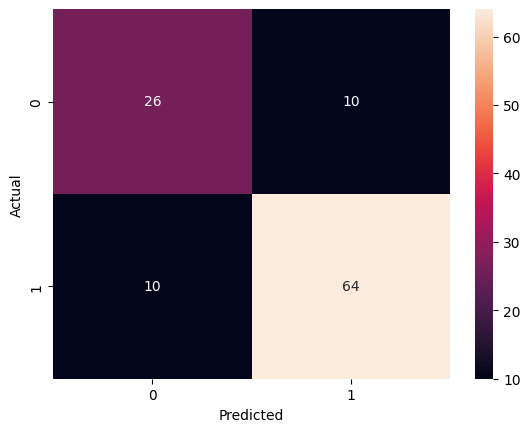

In [16]:
sns.heatmap(cm,annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()